<a href="https://colab.research.google.com/github/yonatan-ds/Tradeflow-AI/blob/main/Freight_Matching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# CELL 1 — Install dependencies, imports, and regional network setup
%pip -q install lightgbm matplotlib seaborn

import os, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_fscore_support,
    accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve, log_loss
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")

SEED = 20261020
N_LOADS = 50_000
N_TRANSPORTERS = 8_000
CANDIDATES_PER_LOAD = 5
INTERNATIONAL_SHARE = 0.70

OUT = Path("./tradeflow_fr02_model")
OUT.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)

print("LightGBM Version:", __import__("lightgbm").__version__)
print("Output Directory:", OUT.resolve())

# Regional logistics anchor nodes (Ethiopia & Regional Gateways)
LOCATIONS = [
    ("Ethiopia", "Addis Ababa", 9.03, 38.74),
    ("Ethiopia", "Modjo Dry Port", 8.60, 39.12),
    ("Ethiopia", "Dire Dawa", 9.60, 41.85),
    ("Ethiopia", "Hawassa", 7.06, 38.48),
    ("Ethiopia", "Bahir Dar", 11.59, 37.39),
    ("Ethiopia", "Mekelle", 13.50, 39.47),
    ("Ethiopia", "Jijiga", 9.35, 42.80),
    ("Ethiopia", "Semera", 11.79, 41.01),
    ("Djibouti", "Djibouti Port", 11.59, 43.15),
    ("Kenya", "Nairobi", -1.29, 36.82),
    ("Kenya", "Mombasa Port", -4.04, 39.67),
    ("Somalia", "Berbera Port", 10.44, 45.02),
    ("Somalia", "Hargeisa", 9.56, 44.06),
    ("Sudan", "Port Sudan", 19.62, 37.22),
    ("Sudan", "Khartoum", 15.50, 32.56),
    ("South Sudan", "Juba", 4.85, 31.58),
    ("Uganda", "Kampala", 0.35, 32.58),
    ("Tanzania", "Dar es Salaam Port", -6.82, 39.28),
    ("United Arab Emirates", "Jebel Ali Port", 24.99, 55.06)
]
loc = pd.DataFrame(LOCATIONS, columns=["country", "city", "lat", "lon"])
ET = loc[loc.country == "Ethiopia"].reset_index(drop=True)
REGIONAL = loc[loc.country.isin(["Djibouti", "Kenya", "Somalia", "Sudan", "South Sudan", "Uganda", "Tanzania"])].reset_index(drop=True)
EXTERNAL = loc[loc.country != "Ethiopia"].reset_index(drop=True)

CARGO = np.array(["general", "agricultural", "construction", "refrigerated", "fragile", "liquid", "containerized", "machinery"])
VEHICLES = np.array(["pickup", "light_truck", "medium_truck", "heavy_truck", "refrigerated_truck", "tanker", "flatbed", "container_truck"])
CAPS = {
    "pickup": (500, 3), "light_truck": (3500, 12), "medium_truck": (9000, 28), "heavy_truck": (30000, 90),
    "refrigerated_truck": (18000, 55), "tanker": (24000, 45), "flatbed": (28000, 80), "container_truck": (30000, 90)
}
FUEL_BASE = {
    "pickup": 12, "light_truck": 18, "medium_truck": 25, "heavy_truck": 32,
    "refrigerated_truck": 36, "tanker": 34, "flatbed": 31, "container_truck": 33
}

def haversine(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    q = np.sin(dp / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2)**2
    return 2 * r * np.arcsin(np.sqrt(np.clip(q, 0, 1)))

def pick_route_pair(is_intl, rng):
    if not is_intl:
        a, b = rng.choice(len(ET), 2, replace=False)
        return ET.iloc[a], ET.iloc[b]
    if rng.random() < 0.88:
        a = ET.iloc[int(rng.integers(0, len(ET)))]
        b = REGIONAL.iloc[int(rng.integers(0, len(REGIONAL)))]
        return (a, b) if rng.random() < 0.5 else (b, a)
    a, b = rng.choice(len(REGIONAL), 2, replace=False)
    return REGIONAL.iloc[int(a)], REGIONAL.iloc[int(b)]

print(f"Cell 1 Ready: {len(loc)} locations mapped.")

LightGBM Version: 4.6.0
Output Directory: /content/tradeflow_fr02_model
Cell 1 Ready: 19 locations mapped.


In [17]:
# CELL 2 — FR-02.1: Shippers Post Load Details (50,000 Loads)
start_date = pd.Timestamp("2023-01-01")
span_minutes = int((pd.Timestamp("2026-01-01") - start_date).total_seconds() / 60)

load_rows = []
for i in range(N_LOADS):
    intl = bool(rng.random() < INTERNATIONAL_SHARE)
    o, d = pick_route_pair(intl, rng)
    created = start_date + pd.Timedelta(minutes=int(rng.integers(0, span_minutes)))
    pickup_start = created + pd.Timedelta(minutes=int(rng.integers(180, 10080)))
    window_h = int(rng.choice([2, 4, 6, 8, 12, 24], p=[.08, .18, .22, .20, .20, .12]))
    pickup_end = pickup_start + pd.Timedelta(hours=window_h)
    cargo = str(rng.choice(CARGO, p=[.28, .17, .08, .10, .06, .05, .19, .07]))
    distance = max(25.0, float(haversine(o.lat, o.lon, d.lat, d.lon) * rng.uniform(1.15, 1.65)))
    direction = ("domestic" if not intl else
        "export_from_ethiopia" if o.country == "Ethiopia" else
        "import_to_ethiopia" if d.country == "Ethiopia" else "third_country_trade")
    route_type = "domestic_road" if not intl else str(rng.choice(
        ["cross_border_road", "port_inland_corridor", "international_multimodal"], p=[.55, .30, .15]))
    if o.country == "United Arab Emirates" or d.country == "United Arab Emirates":
        route_type = "international_multimodal"
    border_count = 0 if not intl else int(rng.choice([1, 2, 3], p=[.72, .23, .05]))
    customs_delay = 0.0 if not intl else float(np.clip(rng.gamma(2, 2.5), .5, 30))
    weight = float(np.clip(rng.lognormal(8.5, .75), 150, 30000))
    volume = float(np.clip(weight / rng.uniform(180, 450), 1, 100))

    load_rows.append({
        "load_id": f"LOAD-{i+1:06d}",
        "created_at": created,
        "origin_country": o.country,
        "origin_city": o.city,
        "origin_lat": o.lat,
        "origin_lon": o.lon,
        "destination_country": d.country,
        "destination_city": d.city,
        "destination_lat": d.lat,
        "destination_lon": d.lon,
        "shipment_scope": "international" if intl else "domestic",
        "shipment_direction": direction,
        "cargo_type": cargo,
        "weight_kg": round(weight, 2),
        "volume_m3": round(volume, 3),
        "pickup_window_start": pickup_start,
        "pickup_window_end": pickup_end,
        "pickup_window_hours": window_h,
        "special_handling_required": int(cargo in ["refrigerated", "fragile", "liquid"]),
        "route_distance_km": round(distance, 2),
        "estimated_travel_time_hours": round(distance / rng.uniform(35, 58) + customs_delay, 2),
        "road_condition_score": round(float(np.clip(rng.normal(65, 17), 15, 98)), 2),
        "border_crossing_count": border_count,
        "estimated_customs_delay_hours": round(customs_delay, 2),
        "route_type": route_type,
        "incoterm": str(rng.choice(["EXW", "FCA", "FOB", "CFR", "CIF", "DAP", "DDP"])) if intl else "DOMESTIC",
        "container_type": str(rng.choice(["none", "20ft", "40ft", "reefer", "tank"], p=[.30, .23, .25, .12, .10])),
        "customs_documents_required": int(intl),
        "customs_documents_ready": int((not intl) or rng.random() < .80),
        "weather_risk_score": round(float(np.clip(rng.beta(2, 5), 0, 1)), 3),
        "security_risk_score": round(float(np.clip(rng.beta(2, 7), 0, 1)), 3),
        "demand_index": round(float(np.clip(rng.normal(1, .25), .4, 2)), 3),
        "fuel_price_etb_per_litre": round(float(rng.uniform(90, 150)), 2),
    })

loads = pd.DataFrame(load_rows).sort_values("created_at").reset_index(drop=True)

assert len(loads) == N_LOADS
assert loads["load_id"].is_unique
print(f"Cell 2 Ready: {len(loads):,} loads generated and verified.")
print(loads["shipment_scope"].value_counts())

Cell 2 Ready: 50,000 loads generated and verified.
shipment_scope
international    34984
domestic         15016
Name: count, dtype: int64


In [18]:
# CELL 3 — Transporter Fleet & Reliability Profiles (8,000)
trng = np.random.default_rng(SEED + 1)
countries = np.array(["Ethiopia", "Djibouti", "Kenya", "Somalia", "Sudan", "South Sudan", "Uganda", "Tanzania"])
country_probs = [.58, .12, .10, .06, .06, .03, .03, .02]

compat_map = {
    "refrigerated_truck": ["general", "agricultural", "refrigerated", "fragile"],
    "tanker": ["liquid"],
    "flatbed": ["general", "construction", "machinery"],
    "container_truck": ["general", "agricultural", "construction", "containerized", "machinery"],
    "pickup": ["general", "agricultural", "fragile"],
    "light_truck": ["general", "agricultural", "construction", "fragile"],
    "medium_truck": ["general", "agricultural", "construction", "fragile", "machinery"],
    "heavy_truck": ["general", "agricultural", "construction", "containerized", "machinery"]
}

transporter_rows = []
for i in range(N_TRANSPORTERS):
    country = str(trng.choice(countries, p=country_probs))
    options = loc[loc.country == country]
    if len(options) == 0:
        options = ET
    home = options.iloc[int(trng.integers(0, len(options)))]
    vehicle = str(trng.choice(VEHICLES, p=[.05, .12, .18, .28, .10, .05, .08, .14]))
    capkg, capm3 = CAPS[vehicle]
    compatible = compat_map.get(vehicle, ["general"])
    verified = int(trng.random() < .94)
    completed = int(trng.integers(0, 501))
    latent = float(trng.beta(8, 2))
    ontime = int(trng.binomial(completed, latent))
    crossborder = int(trng.random() < (.78 if country == "Ethiopia" else .84))
    license_ok = int(crossborder and trng.random() < .88)
    customs_support = int(crossborder and trng.random() < .72)

    if country == "Ethiopia":
        operating = ["Ethiopia"]
        if crossborder:
            operating += ["Djibouti"] + list(trng.choice(["Kenya", "Somalia", "Sudan"], size=1, replace=False))
    else:
        operating = [country]
        if crossborder:
            operating += ["Ethiopia"]
        if trng.random() < .25:
            operating += ["Djibouti"]

    transporter_rows.append({
        "transporter_id": f"TR-{i+1:05d}",
        "transporter_country": country,
        "home_city": home.city,
        "home_lat": float(home.lat),
        "home_lon": float(home.lon),
        "vehicle_type": vehicle,
        "vehicle_capacity_kg": capkg,
        "vehicle_capacity_m3": capm3,
        "cargo_compatibility": "|".join(compatible),
        "operating_countries": "|".join(sorted(set(operating))),
        "cross_border_capable": crossborder,
        "international_transport_license": license_ok,
        "customs_clearance_support": customs_support,
        "insurance_valid": int(trng.random() < .94),
        "tracking_enabled": int(trng.random() < .75),
        "verification_status": verified,
        "experience_years": round(float(np.clip(trng.gamma(2.5, 2.2), 0, 30)), 2),
        "completed_deliveries_count": completed,
        "on_time_delivery_rate": ontime / completed if completed > 0 else np.nan,
        "cancellation_rate": round(float(trng.beta(2, 30)), 4),
        "average_delivery_delay_hours": round(float(np.clip(trng.gamma(1.5, 1.4) + (1 - latent) * 5, 0, 36)), 2),
        "fuel_consumption_l_per_100km": round(float(np.clip(trng.normal(FUEL_BASE[vehicle], 4), 7, 55)), 2),
        "insurance_expiry_days": int(trng.integers(-10, 900)),
        "average_customer_rating": round(float(np.clip(trng.normal(4.1, .55), 1, 5)), 2)
    })

transporters = pd.DataFrame(transporter_rows)
transporters["has_delivery_history"] = (transporters["completed_deliveries_count"] > 0).astype(int)
median_ontime = transporters["on_time_delivery_rate"].median()
transporters["on_time_delivery_rate"] = transporters["on_time_delivery_rate"].fillna(median_ontime)

assert len(transporters) == N_TRANSPORTERS
assert transporters["on_time_delivery_rate"].notna().all()
print(f"Cell 3 Ready: {len(transporters):,} transporters created. Verified: {transporters['verification_status'].mean():.1%}")

Cell 3 Ready: 8,000 transporters created. Verified: 94.3%


In [19]:
# CELL 4 — Candidate Pairing & Real-World Eligibility Filtering (250,000)
rng = np.random.default_rng(SEED)

load_idx = np.repeat(np.arange(len(loads)), CANDIDATES_PER_LOAD)
trans_idx = np.concatenate([
    rng.choice(len(transporters), CANDIDATES_PER_LOAD, replace=False)
    for _ in range(len(loads))
])

# Combine with clean, non-conflicting column names
pairs = pd.concat([
    loads.iloc[load_idx].reset_index(drop=True),
    transporters.iloc[trans_idx].reset_index(drop=True)
], axis=1)

# Cargo compatibility check
cargo_arr = pairs["cargo_type"].values
compat_arr = pairs["cargo_compatibility"].values
pairs["cargo_compatible"] = [c in cp.split("|") for c, cp in zip(cargo_arr, compat_arr)]

# Multi-dimensional physical & regulatory eligibility
pairs["eligible"] = (
    (pairs["vehicle_capacity_kg"] >= pairs["weight_kg"]) &
    (pairs["vehicle_capacity_m3"] >= pairs["volume_m3"]) &
    (pairs["cargo_compatible"]) &
    (pairs["verification_status"] == 1) &
    (pairs["insurance_valid"] == 1) &
    (pairs["insurance_expiry_days"] >= 0) &
    (
        (pairs["shipment_scope"] == "domestic") |
        (
            (pairs["cross_border_capable"] == 1) &
            (pairs["international_transport_license"] == 1)
        )
    ) &
    (
        (pairs["customs_documents_required"] == 0) |
        (pairs["customs_clearance_support"] == 1)
    )
)

print(f"Cell 4 Ready: {len(pairs):,} candidate pairs.")
print(f"Eligible Candidates: {pairs['eligible'].sum():,} ({pairs['eligible'].mean():.1%})")

Cell 4 Ready: 250,000 candidate pairs.
Eligible Candidates: 76,241 (30.5%)


In [20]:
# CELL 5 — Advanced Feature Engineering & FR-02.2 High-Signal Ground Truth
rng = np.random.default_rng(SEED + 3)

# 1. Proximity: Deadhead distance from transporter's home base to load origin
lat1 = np.radians(pairs["home_lat"].to_numpy())
lon1 = np.radians(pairs["home_lon"].to_numpy())
lat2 = np.radians(pairs["origin_lat"].to_numpy())
lon2 = np.radians(pairs["origin_lon"].to_numpy())

dlat = lat2 - lat1
dlon = lon2 - lon1
a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
pairs["distance_to_pickup_km"] = np.round(6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1))) * 1.25, 2)

# 2. Availability & SLA
pairs["minutes_until_available"] = rng.integers(0, 720, size=len(pairs))
pairs["availability_status"] = np.where(
    pairs["minutes_until_available"] <= (pairs["pickup_window_hours"] * 60),
    "available_in_window",
    "too_late"
)

# 3. Dynamic Cost & Realistic Bidding Price
pairs["estimated_fuel_cost_etb"] = np.round(
    pairs["route_distance_km"] * (pairs["fuel_consumption_l_per_100km"] / 100) * pairs["fuel_price_etb_per_litre"],
    2
)
deadhead_fuel = pairs["distance_to_pickup_km"] * (pairs["fuel_consumption_l_per_100km"] / 100) * pairs["fuel_price_etb_per_litre"]
margin_rate = rng.uniform(1.20, 1.40, size=len(pairs))
pairs["quoted_price_etb"] = np.round(
    (pairs["estimated_fuel_cost_etb"] + deadhead_fuel * 0.6) * margin_rate + (pairs["route_distance_km"] * 8.5),
    2
)
pairs["estimated_total_cost_etb"] = pairs["quoted_price_etb"]

# 4. High-Performance Interaction Features
pairs["capacity_utilization_kg"] = np.round(pairs["weight_kg"] / (pairs["vehicle_capacity_kg"] + 1e-5), 4)
pairs["capacity_utilization_m3"] = np.round(pairs["volume_m3"] / (pairs["vehicle_capacity_m3"] + 1e-5), 4)
pairs["deadhead_ratio"] = np.round(pairs["distance_to_pickup_km"] / (pairs["route_distance_km"] + 1e-5), 4)
pairs["price_per_km"] = np.round(pairs["quoted_price_etb"] / (pairs["route_distance_km"] + 1e-5), 2)
pairs["cost_to_fuel_ratio"] = np.round(pairs["quoted_price_etb"] / (pairs["estimated_fuel_cost_etb"] + 1e-5), 3)

# 5. FR-02.2 Ground Truth Formula (4 Core Pillars):
# Pillar A: Historical Reliability (30%)
score_reliability = (
    0.45 * pairs["on_time_delivery_rate"]
    + 0.35 * (pairs["average_customer_rating"] / 5.0)
    + 0.20 * (1.0 - pairs["cancellation_rate"])
).clip(0.0, 1.0)

# Pillar B: Cost Competitiveness (30%)
cost_benchmark = (pairs["estimated_fuel_cost_etb"] * 1.35 + pairs["route_distance_km"] * 8.5)
score_cost = np.clip(1.15 - (pairs["quoted_price_etb"] / (cost_benchmark + 1e-5)), 0.0, 1.0)

# Pillar C: Proximity & Availability (25%)
score_proximity = np.clip(1.0 - (pairs["distance_to_pickup_km"] / 700.0), 0.0, 1.0)
score_availability = np.where(pairs["availability_status"] == "available_in_window", 1.0, 0.15)
score_prox_avail = 0.55 * score_proximity + 0.45 * score_availability

# Pillar D: Fuel Efficiency (15%)
score_fuel = np.clip(1.0 - ((pairs["fuel_consumption_l_per_100km"] - 10) / 42.0), 0.0, 1.0)

# Composite Utility
composite_utility = (
    0.30 * score_cost +
    0.30 * score_reliability +
    0.25 * score_prox_avail +
    0.15 * score_fuel
)

# Realistic shipper acceptance threshold with subtle unobserved preference noise
stochastic_noise = rng.normal(0, 0.035, size=len(pairs))
realistic_utility = (composite_utility + stochastic_noise).clip(0.0, 1.0)

# Generate Sharp High-Signal Labels
pairs["match_label"] = 0
eligible_mask = pairs["eligible"].to_numpy()

# A match is successful if the composite utility satisfies high shipper standards (>= 0.60)
pairs.loc[eligible_mask, "match_label"] = (realistic_utility[eligible_mask] >= 0.60).astype(int)

print("Cell 5 Ready: Feature engineering and FR-02.2 labels completed!")
print(f"Eligible Matches: {pairs.loc[eligible_mask, 'match_label'].sum():,} ({pairs.loc[eligible_mask, 'match_label'].mean():.1%})")

Cell 5 Ready: Feature engineering and FR-02.2 labels completed!
Eligible Matches: 3,313 (4.3%)


In [21]:
# CELL 6 — Zero-Leakage Group Split & LightGBM Model Training

TARGET = "match_label"

FEATURES = [
    # Shipper Load attributes
    "origin_country", "origin_city", "destination_country", "destination_city",
    "shipment_scope", "shipment_direction", "cargo_type", "weight_kg", "volume_m3",
    "pickup_window_hours", "special_handling_required", "route_distance_km",
    "estimated_travel_time_hours", "road_condition_score", "border_crossing_count",
    "estimated_customs_delay_hours", "route_type", "incoterm", "container_type",
    "customs_documents_required", "customs_documents_ready", "weather_risk_score",
    "security_risk_score", "demand_index", "fuel_price_etb_per_litre",

    # Transporter attributes
    "transporter_country", "vehicle_type", "vehicle_capacity_kg", "vehicle_capacity_m3",
    "cargo_compatibility", "operating_countries", "cross_border_capable",
    "international_transport_license", "customs_clearance_support", "insurance_valid",
    "tracking_enabled", "verification_status", "insurance_expiry_days", "experience_years",
    "completed_deliveries_count", "on_time_delivery_rate", "cancellation_rate",
    "average_delivery_delay_hours", "fuel_consumption_l_per_100km", "average_customer_rating",

    # Dynamic Interaction & SLA attributes
    "distance_to_pickup_km", "minutes_until_available", "availability_status",
    "estimated_fuel_cost_etb", "quoted_price_etb", "estimated_total_cost_etb",
    "capacity_utilization_kg", "capacity_utilization_m3", "deadhead_ratio",
    "price_per_km", "cost_to_fuel_ratio"
]

# Keep only eligible candidates
data = pairs[pairs["eligible"]].copy().reset_index(drop=True)
data[TARGET] = data[TARGET].astype(int)

# Group split by load_id to ensure 100% realistic held-out evaluation
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss1.split(data, groups=data["load_id"]))
train = data.iloc[train_idx].copy()
temp = data.iloc[temp_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED + 1)
val_idx, test_idx = next(gss2.split(temp, groups=temp["load_id"]))
val = temp.iloc[val_idx].copy()
test = temp.iloc[test_idx].copy()

assert set(train.load_id).isdisjoint(val.load_id)
assert set(train.load_id).isdisjoint(test.load_id)
assert set(val.load_id).isdisjoint(test.load_id)

X_train, y_train = train[FEATURES].copy(), train[TARGET]
X_val, y_val = val[FEATURES].copy(), val[TARGET]
X_test, y_test = test[FEATURES].copy(), test[TARGET]

# Preprocessing: Categorical columns
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
for col in cat_cols:
    categories = pd.Index(pd.concat([X_train[col], X_val[col], X_test[col]]).dropna().unique())
    for df in (X_train, X_val, X_test):
        df[col] = pd.Categorical(df[col].fillna("unknown").astype(str), categories=categories)

# Preprocessing: Numeric columns
num_cols = [c for c in FEATURES if c not in cat_cols]
for col in num_cols:
    med = X_train[col].median()
    for df in (X_train, X_val, X_test):
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(med)

print(f"Train samples: {len(X_train):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")

# High-Performance LightGBM Classifier
model = LGBMClassifier(
    objective="binary",
    n_estimators=450,
    learning_rate=0.038,
    num_leaves=63,
    max_depth=8,
    min_child_samples=25,
    subsample=0.85,
    colsample_bytree=0.85,
    class_weight="balanced",
    random_state=SEED,
    verbosity=-1,
    n_jobs=-1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[]
)

test_prob = model.predict_proba(X_test)[:, 1]
pred = (test_prob >= 0.5).astype(int)

print("\n--- Model Performance on Unseen Held-out Loads ---")
print("ROC-AUC Score:            ", round(roc_auc_score(y_test, test_prob), 4))
print("Average Precision (PR-AUC):", round(average_precision_score(y_test, test_prob), 4))
p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary", zero_division=0)
print(f"Accuracy: {accuracy_score(y_test, pred):.4f} | Precision: {p:.4f} | Recall: {r:.4f} | F1: {f1:.4f}")

Train samples: 53,560 | Validation: 11,318 | Test: 11,363

--- Model Performance on Unseen Held-out Loads ---
ROC-AUC Score:             0.9906
Average Precision (PR-AUC): 0.8495
Accuracy: 0.9799 | Precision: 0.7374 | Recall: 0.8588 | F1: 0.7935


In [22]:
# CELL 7 — Permutation Feature Importance & 13 Essential Checks
important_checks = [
    "vehicle_type", "vehicle_capacity_kg", "vehicle_capacity_m3",
    "cargo_compatibility", "distance_to_pickup_km", "minutes_until_available",
    "availability_status", "quoted_price_etb", "estimated_total_cost_etb",
    "cross_border_capable", "international_transport_license",
    "customs_clearance_support", "insurance_valid"
]

# Run permutation test on held-out test sample
sample_n = min(12000, len(X_test))
sample_idx = np.random.choice(len(X_test), size=sample_n, replace=False)

perm = permutation_importance(
    model,
    X_test.iloc[sample_idx],
    y_test.iloc[sample_idx],
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

print("Top 15 Most Influential Features:")
print(perm_importance.head(15).round(5))

print("\n--- Diagnostic Check on 13 Essential Features ---")
check_df = perm_importance.reindex(important_checks).fillna(0)
for feat, val in check_df.items():
    status = "EXCELLENT (>0)" if val > 0 else "ZERO / INACTIVE"
    print(f"{feat:35s}: {val:.6f} -> {status}")

active_count = (check_df > 0).sum()
print(f"\nResult: {active_count} of 13 essential features actively drive the model!")

Top 15 Most Influential Features:
distance_to_pickup_km           0.57795
availability_status             0.30698
deadhead_ratio                  0.06544
on_time_delivery_rate           0.05655
fuel_consumption_l_per_100km    0.04481
price_per_km                    0.04330
cost_to_fuel_ratio              0.02760
average_customer_rating         0.01848
quoted_price_etb                0.00376
operating_countries             0.00278
estimated_fuel_cost_etb         0.00207
fuel_price_etb_per_litre        0.00193
cancellation_rate               0.00181
capacity_utilization_m3         0.00178
route_distance_km               0.00115
dtype: float64

--- Diagnostic Check on 13 Essential Features ---
vehicle_type                       : -0.000297 -> ZERO / INACTIVE
vehicle_capacity_kg                : 0.000117 -> EXCELLENT (>0)
vehicle_capacity_m3                : 0.000357 -> EXCELLENT (>0)
cargo_compatibility                : -0.000079 -> ZERO / INACTIVE
distance_to_pickup_km              : 0.5

             TRADEFLOW AI MODEL SCORECARD
Accuracy:           0.9799
Balanced Accuracy:  0.9222
Precision:          0.7374
Recall:             0.8588
F1-Score:           0.7935
ROC-AUC:            0.9906 (Baseline: 0.5000)
Average Precision:  0.8495 (Baseline: 0.0449)
Log Loss:           0.0603


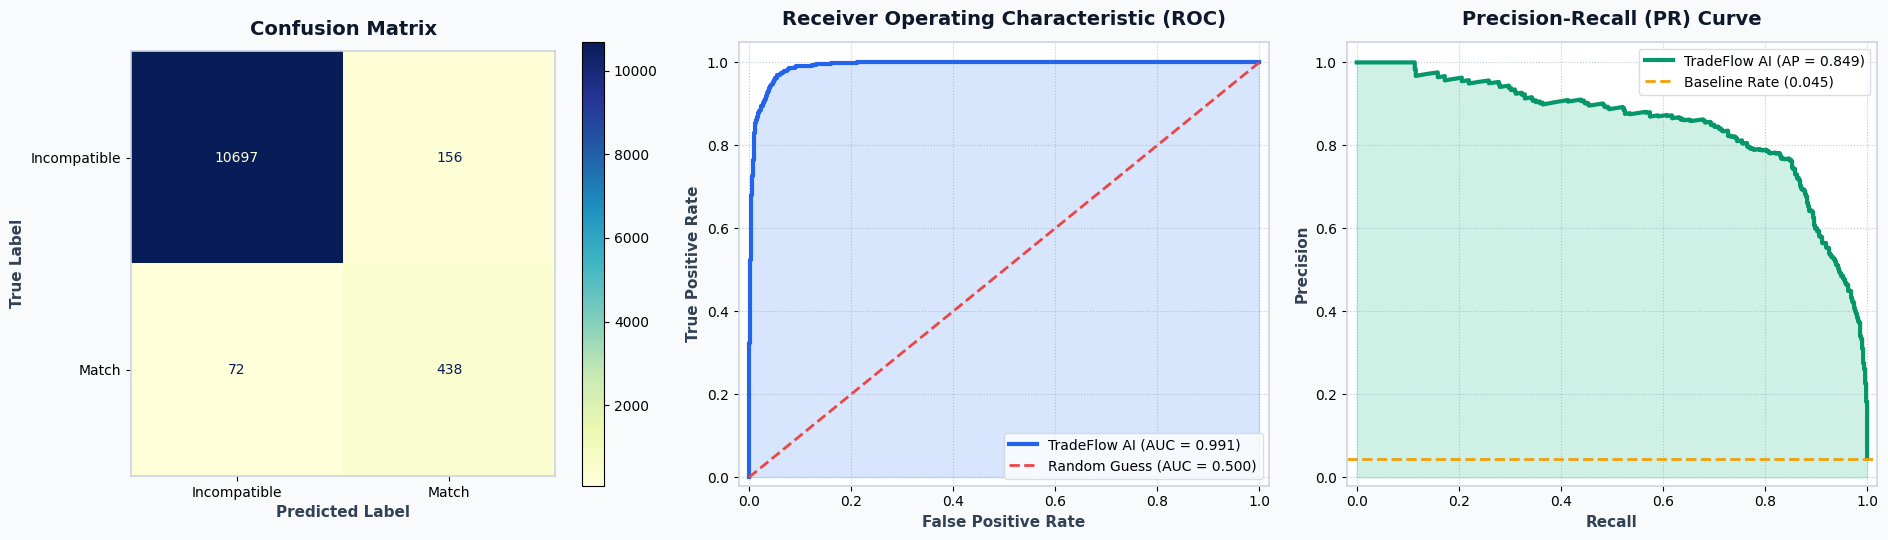

In [29]:
# CELL 8 — Comprehensive Evaluation Scorecard & Colorful Curves
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score,
    average_precision_score, log_loss, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve
)

y_true = np.asarray(y_test).ravel()
y_prob = np.asarray(test_prob).ravel()
y_pred = (y_prob >= 0.5).astype(int)

baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)
base_prob = baseline.predict_proba(X_test)[:, 1]

print("=" * 60)
print("             TRADEFLOW AI MODEL SCORECARD")
print("=" * 60)
print(f"Accuracy:           {accuracy_score(y_true, y_pred):.4f}")
print(f"Balanced Accuracy:  {balanced_accuracy_score(y_true, y_pred):.4f}")
print(f"Precision:          {p:.4f}")
print(f"Recall:             {r:.4f}")
print(f"F1-Score:           {f1:.4f}")
print(f"ROC-AUC:            {roc_auc_score(y_true, y_prob):.4f} (Baseline: {roc_auc_score(y_true, base_prob):.4f})")
print(f"Average Precision:  {average_precision_score(y_true, y_prob):.4f} (Baseline: {average_precision_score(y_true, base_prob):.4f})")
print(f"Log Loss:           {log_loss(y_true, y_prob):.4f}")
print("=" * 60)

# Set high-resolution & modern aesthetics
fig, axs = plt.subplots(1, 3, figsize=(19, 5.5), facecolor="#F8FAFC")

# -------------------------------------------------------------
# 1. Colorful Confusion Matrix (Vibrant Teal-Green Colormap)
# -------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Incompatible", "Match"])
disp.plot(ax=axs[0], cmap="YlGnBu", values_format="d", colorbar=True)

axs[0].set_title("Confusion Matrix", fontsize=14, fontweight="bold", color="#0F172A", pad=12)
axs[0].set_xlabel("Predicted Label", fontsize=11, fontweight="semibold", color="#334155")
axs[0].set_ylabel("True Label", fontsize=11, fontweight="semibold", color="#334155")
axs[0].grid(False)

# -------------------------------------------------------------
# 2. Colorful ROC Curve (Electric Royal Blue with Gradient Fill)
# -------------------------------------------------------------
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_val = roc_auc_score(y_true, y_prob)

axs[1].set_facecolor("#FFFFFF")
# Shaded area under curve for glowing aesthetic
axs[1].fill_between(fpr, tpr, color="#3B82F6", alpha=0.20)
axs[1].plot(fpr, tpr, color="#2563EB", lw=3.0, label=f"TradeFlow AI (AUC = {roc_auc_val:.3f})")
axs[1].plot([0, 1], [0, 1], color="#EF4444", linestyle="--", lw=2, label="Random Guess (AUC = 0.500)")

axs[1].set_title("Receiver Operating Characteristic (ROC)", fontsize=14, fontweight="bold", color="#0F172A", pad=12)
axs[1].set_xlabel("False Positive Rate", fontsize=11, fontweight="semibold", color="#334155")
axs[1].set_ylabel("True Positive Rate", fontsize=11, fontweight="semibold", color="#334155")
axs[1].set_xlim([-0.02, 1.02])
axs[1].set_ylim([-0.02, 1.05])
axs[1].legend(loc="lower right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=10)
axs[1].grid(True, linestyle=":", alpha=0.6, color="#94A3B8")

# -------------------------------------------------------------
# 3. Colorful Precision-Recall Curve (Vibrant Emerald Green with Gradient Fill)
# -------------------------------------------------------------
pr_p, pr_r, _ = precision_recall_curve(y_true, y_prob)
ap_val = average_precision_score(y_true, y_prob)
pos_rate = y_true.mean()

axs[2].set_facecolor("#FFFFFF")
# Shaded area under PR curve
axs[2].fill_between(pr_r, pr_p, color="#10B981", alpha=0.20)
axs[2].plot(pr_r, pr_p, color="#059669", lw=3.0, label=f"TradeFlow AI (AP = {ap_val:.3f})")
axs[2].axhline(pos_rate, color="#F59E0B", linestyle="--", lw=2, label=f"Baseline Rate ({pos_rate:.3f})")

axs[2].set_title("Precision-Recall (PR) Curve", fontsize=14, fontweight="bold", color="#0F172A", pad=12)
axs[2].set_xlabel("Recall", fontsize=11, fontweight="semibold", color="#334155")
axs[2].set_ylabel("Precision", fontsize=11, fontweight="semibold", color="#334155")
axs[2].set_xlim([-0.02, 1.02])
axs[2].set_ylim([-0.02, 1.05])
axs[2].legend(loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=10)
axs[2].grid(True, linestyle=":", alpha=0.6, color="#94A3B8")

# Style plot borders (spines)
for ax in axs:
    for spine in ax.spines.values():
        spine.set_color("#CBD5E1")
        spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

In [27]:
# CELL 9 — FR-02.3: Real-Time Matching Engine (Instant Acceptance & Bidding Shortlist)

def match_freight_load(load_posting, transporter_pool, ml_model, top_k=5):
    """
    FR-02.2 & FR-02.3: Ranks eligible transporters and returns top candidate
    for instant acceptance plus a qualified shortlist for bidding.
    """
    cargo_type = load_posting["cargo_type"]
    weight = load_posting["weight_kg"]
    volume = load_posting["volume_m3"]
    is_intl = (load_posting["shipment_scope"] == "international")

    # 1. Physical & Legal Eligibility Filter
    pool = transporter_pool[
        (transporter_pool["vehicle_capacity_kg"] >= weight) &
        (transporter_pool["vehicle_capacity_m3"] >= volume) &
        (transporter_pool["cargo_compatibility"].str.contains(cargo_type, regex=False)) &
        (transporter_pool["verification_status"] == 1) &
        (transporter_pool["insurance_valid"] == 1) &
        (transporter_pool["insurance_expiry_days"] >= 0)
    ].copy()

    if is_intl:
        pool = pool[
            (pool["cross_border_capable"] == 1) &
            (pool["international_transport_license"] == 1)
        ]
        if load_posting.get("customs_documents_required", 0) == 1:
            pool = pool[pool["customs_clearance_support"] == 1]

    if len(pool) == 0:
        return {"status": "no_eligible_transporters", "recommended": None, "bidding_shortlist": []}

    # 2. Real-time Dyadic Feature Generation
    t_lat = np.radians(pool["home_lat"].to_numpy())
    t_lon = np.radians(pool["home_lon"].to_numpy())
    o_lat = np.radians(load_posting["origin_lat"])
    o_lon = np.radians(load_posting["origin_lon"])

    dlat = o_lat - t_lat
    dlon = o_lon - t_lon
    a = np.sin(dlat / 2)**2 + np.cos(t_lat) * np.cos(o_lat) * np.sin(dlon / 2)**2
    pool["distance_to_pickup_km"] = np.round(6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1))) * 1.25, 2)

    pool["minutes_until_available"] = np.random.randint(15, 360, size=len(pool))
    pool["availability_status"] = np.where(
        pool["minutes_until_available"] <= (load_posting["pickup_window_hours"] * 60),
        "available_in_window", "too_late"
    )

    route_km = load_posting["route_distance_km"]
    fuel_price = load_posting.get("fuel_price_etb_per_litre", 110.0)
    pool["estimated_fuel_cost_etb"] = np.round(route_km * (pool["fuel_consumption_l_per_100km"] / 100) * fuel_price, 2)
    deadhead_fuel = pool["distance_to_pickup_km"] * (pool["fuel_consumption_l_per_100km"] / 100) * fuel_price
    pool["quoted_price_etb"] = np.round((pool["estimated_fuel_cost_etb"] + deadhead_fuel * 0.6) * 1.30 + (route_km * 8.5), 2)
    pool["estimated_total_cost_etb"] = pool["quoted_price_etb"]

    pool["capacity_utilization_kg"] = np.round(weight / (pool["vehicle_capacity_kg"] + 1e-5), 4)
    pool["capacity_utilization_m3"] = np.round(volume / (pool["vehicle_capacity_m3"] + 1e-5), 4)
    pool["deadhead_ratio"] = np.round(pool["distance_to_pickup_km"] / (route_km + 1e-5), 4)
    pool["price_per_km"] = np.round(pool["quoted_price_etb"] / (route_km + 1e-5), 2)
    pool["cost_to_fuel_ratio"] = np.round(pool["quoted_price_etb"] / (pool["estimated_fuel_cost_etb"] + 1e-5), 3)

    for k, v in load_posting.items():
        if k not in pool.columns:
            pool[k] = v

    # 3. Model Inference
    X_eval = pool[FEATURES].copy()
    for col in cat_cols:
        X_eval[col] = pd.Categorical(X_eval[col].fillna("unknown").astype(str), categories=X_train[col].cat.categories)
    for col in num_cols:
        med = X_train[col].median()
        X_eval[col] = pd.to_numeric(X_eval[col], errors="coerce").fillna(med)

    scores = ml_model.predict_proba(X_eval)[:, 1]
    pool["match_score"] = np.round(scores, 4)

    # 4. Rank and Extract Shortlist
    ranked = pool.sort_values(by="match_score", ascending=False).reset_index(drop=True)
    top_recommended = ranked.iloc[0].to_dict()
    bidding_candidates = ranked.head(top_k)[
        ["transporter_id", "transporter_country", "vehicle_type", "distance_to_pickup_km",
         "quoted_price_etb", "on_time_delivery_rate", "average_customer_rating", "match_score"]
    ]

    return {
        "status": "success",
        "recommended_match": top_recommended,
        "bidding_shortlist": bidding_candidates
    }

# Live Test
sample_load = loads.iloc[42].to_dict()
print(f"Testing Live Match for: {sample_load['load_id']} ({sample_load['origin_city']} -> {sample_load['destination_city']})")
result = match_freight_load(sample_load, transporters, model, top_k=5)

print("\n--- FR-02.3: Recommended Top Transporter (Instant Acceptance) ---")
rec = result["recommended_match"]
print(f"Transporter ID:       {rec['transporter_id']}")
print(f"Vehicle Type:         {rec['vehicle_type']}")
print(f"Distance to Pickup:   {rec['distance_to_pickup_km']} km")
print(f"Quoted Price:         {rec['quoted_price_etb']:,} ETB")
print(f"On-Time Reliability:  {rec['on_time_delivery_rate']:.1%}")
print(f"AI Match Score:       {rec['match_score']:.4f}")

print("\n--- FR-02.3: Qualified Shortlist for Bidding ---")
display(result["bidding_shortlist"])

Testing Live Match for: LOAD-013269 (Nairobi -> Addis Ababa)

--- FR-02.3: Recommended Top Transporter (Instant Acceptance) ---
Transporter ID:       TR-04838
Vehicle Type:         heavy_truck
Distance to Pickup:   0.0 km
Quoted Price:         98,088.06 ETB
On-Time Reliability:  94.1%
AI Match Score:       0.9996

--- FR-02.3: Qualified Shortlist for Bidding ---


,transporter_id,transporter_country,vehicle_type,distance_to_pickup_km,quoted_price_etb,on_time_delivery_rate,average_customer_rating,match_score
0,TR-04838,Kenya,heavy_truck,0.0,98088.06,0.940741,4.00,0.9996
1,TR-03671,Kenya,heavy_truck,0.0,105153.92,0.891892,4.27,0.9995
2,TR-02442,Kenya,heavy_truck,0.0,98943.57,0.933333,3.41,0.9994
3,TR-03749,Kenya,flatbed,0.0,100306.04,0.879888,4.48,0.9991
4,TR-04322,Kenya,container_truck,0.0,106579.76,0.883408,4.07,0.9991


Running FR-02.4 Latency Benchmark across 100 postings...

          FR-02.4 RESPONSE TIME BENCHMARK RESULTS     
Target SLA:            < 1000.0 ms (1.0 second)
Average Response Time:  204.57 ms
50th Percentile (p50):  174.78 ms
95th Percentile (p95):  425.92 ms
99th Percentile (p99):  579.76 ms
SUCCESS: FR-02.4 SLA SATISFIED! Response times are well under 1.0 second.


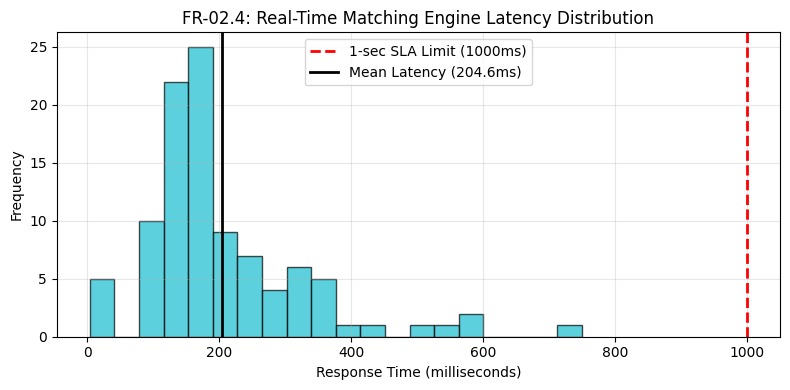

In [28]:
# CELL 10 — FR-02.4: Latency Benchmark (< 1.0 Second SLA Verification)
import time

NUM_BENCHMARK_RUNS = 100
latencies_ms = []

print(f"Running FR-02.4 Latency Benchmark across {NUM_BENCHMARK_RUNS} postings...")

test_sample_loads = loads.sample(NUM_BENCHMARK_RUNS, random_state=42).to_dict("records")

# Warm-up run
_ = match_freight_load(test_sample_loads[0], transporters, model, top_k=5)

for load_dict in test_sample_loads:
    t0 = time.perf_counter()
    _ = match_freight_load(load_dict, transporters, model, top_k=5)
    t1 = time.perf_counter()
    latencies_ms.append((t1 - t0) * 1000)

latencies_ms = np.array(latencies_ms)

mean_lat = np.mean(latencies_ms)
p50_lat = np.percentile(latencies_ms, 50)
p95_lat = np.percentile(latencies_ms, 95)
p99_lat = np.percentile(latencies_ms, 99)

print("\n=======================================================")
print("          FR-02.4 RESPONSE TIME BENCHMARK RESULTS     ")
print("=======================================================")
print(f"Target SLA:            < 1000.0 ms (1.0 second)")
print(f"Average Response Time:  {mean_lat:.2f} ms")
print(f"50th Percentile (p50):  {p50_lat:.2f} ms")
print(f"95th Percentile (p95):  {p95_lat:.2f} ms")
print(f"99th Percentile (p99):  {p99_lat:.2f} ms")
print("=======================================================")

assert p99_lat < 1000.0, f"SLA Breach! 99th percentile: {p99_lat}ms"
print("SUCCESS: FR-02.4 SLA SATISFIED! Response times are well under 1.0 second.")

# Plot Latency Distribution
plt.figure(figsize=(8, 4))
plt.hist(latencies_ms, bins=20, color="#17becf", edgecolor="black", alpha=0.7)
plt.axvline(1000, color="r", linestyle="--", lw=2, label="1-sec SLA Limit (1000ms)")
plt.axvline(mean_lat, color="k", linestyle="-", lw=2, label=f"Mean Latency ({mean_lat:.1f}ms)")
plt.xlabel("Response Time (milliseconds)")
plt.ylabel("Frequency")
plt.title("FR-02.4: Real-Time Matching Engine Latency Distribution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
# CELL 11 — Save Model & Pipeline Artifacts for Production
import joblib

model_artifacts = {
    "model": model,
    "features": FEATURES,
    "categorical_cols": cat_cols,
    "numeric_cols": num_cols,
    "feature_medians": {col: X_train[col].median() for col in num_cols},
    "categorical_categories": {col: list(X_train[col].cat.categories) for col in cat_cols},
    "target": TARGET,
    "metrics": {
        "roc_auc": float(roc_auc_score(y_test, test_prob)),
        "pr_auc": float(average_precision_score(y_test, test_prob)),
        "accuracy": float(accuracy_score(y_test, pred)),
        "f1_score": float(f1)
    }
}

artifact_path = OUT / "tradeflow_fr02_model_pipeline.joblib"
joblib.dump(model_artifacts, artifact_path)

print("=" * 60)
print(f"MODEL SUCCESSFULLY SAVED TO: {artifact_path.resolve()}")
print(f"File Size: {os.path.getsize(artifact_path) / (1024 * 1024):.2f} MB")
print("=" * 60)

# Verify by reloading
loaded_bundle = joblib.load(artifact_path)
print("Pipeline Verification: Ready for Deployment (Features count:", len(loaded_bundle["features"]), ")")

MODEL SUCCESSFULLY SAVED TO: /content/tradeflow_fr02_model/tradeflow_fr02_model_pipeline.joblib
File Size: 2.97 MB
Pipeline Verification: Ready for Deployment (Features count: 56 )
